In [2]:
import os
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
import math

In [3]:
from memoria_icm.datos import *
df, df_resumen = cargar_datos()

Datos cargados. Trackeo: (44324, 28), Resumen: (192, 42)


In [4]:
def visualization_by_salinity(df, variable = 'position', dif = False):

    if variable == 'position':
        name_xaxis = 'x_centrada'
        name_yaxis = 'y_centrada'
    else:
        name_xaxis = 't'
        name_yaxis = variable
    
    keys_to_group = ['id_ubicacion', 'especie', 'tratamiento', 'salinidad']
    key_vals = df['salinidad'].unique()
    key_vals = np.concatenate([key_vals[:2],np.sort(key_vals[2:])])
    key_vals = np.concatenate([key_vals[2:][key_vals[2:]<=35],key_vals[:2], key_vals[2:][key_vals[2:]>35]])
    ncols = int(np.ceil(np.sqrt(len(key_vals))))
    nrows = int(np.ceil(len(key_vals) / ncols))
    
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 3 * nrows), sharex=True, sharey=True)
    axs = axs.flatten()
    
    all_groups = df.groupby(['id_ubicacion', 'especie', 'tratamiento'])
    all_names = list(all_groups.groups.keys())
    cmap = plt.get_cmap("tab20", len(all_names))
    color_map = {name: cmap(i) for i, name in enumerate(all_names)}
    
    videos_id = []
    
    for ival, val in enumerate(key_vals):
        
        ax = axs[ival]
        groups = df[df['salinidad'] == val].groupby(keys_to_group)
        
        for idx, (name, group) in enumerate(groups):
    
            ids = group["id"].unique()
            videos_id = np.concatenate([videos_id,ids])
    
            for i in ids:

                traj = group[group["id"] == i]
                
                if dif and (variable != 'position'):
                    ax.plot(traj[name_xaxis][1:], np.diff(traj[name_yaxis]), color=color_map[name[:-1]], label=str(name[:-1]) if i == ids[0] else None)
                elif (dif and (variable == 'position')):
                    print("For position (x,y) not available the diff")
                    return
                else:
                    ax.plot(traj[name_xaxis], traj[name_yaxis], color=color_map[name[:-1]], label=str(name[:-1]) if i == ids[0] else None)


        
        ax.set_title(f'Trajectories for {k} = {val}')
        ax.legend()
    
    plt.tight_layout()
    plt.show()

In [5]:
def visualization_by_other_variables(df, variable = 'position', keys_to_group = ['id_ubicacion', 'especie', 'tratamiento'], dif = False):

    if variable == 'position':
        name_xaxis = 'x_centrada'
        name_yaxis = 'y_centrada'
    else:
        name_xaxis = 't'
        name_yaxis = variable
        
    key_vals = df['salinidad'].unique()
    key_vals = np.concatenate([key_vals[:2],np.sort(key_vals[2:])])
    key_vals = np.concatenate([key_vals[2:][key_vals[2:]<=35],key_vals[:2], key_vals[2:][key_vals[2:]>35]])
    salinidades = key_vals
    cmap = plt.get_cmap("tab20", len(salinidades))
    color_sal = {sal: cmap(i) for i, sal in enumerate([str(s) for s in salinidades])}
    
    ncols = len(keys_to_group)
    nrows = max([len( df['id_ubicacion'].unique()),len( df['especie'].unique()),len( df['tratamiento'].unique())])
    
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 3 * nrows), sharex=True, sharey=True)
    axs = np.atleast_2d(axs)
    
    for ik, k in enumerate(keys_to_group):
        key_vals = df[k].unique()
        
        for ival, val in enumerate(key_vals):
    
            ax = axs[ival, ik]
            groups = df[df[k] == val].groupby('salinidad')
            
            for idx, (name, group) in enumerate(groups):
    
                name_str = str(name)
                ids = group["id"].unique()
                for i in ids:

                    traj = group[group["id"] == i]
                
                    if dif and (variable != 'position'):
                        ax.plot(traj[name_xaxis][1:], np.diff(traj[name_yaxis]), color=color_sal[name_str], label=str(name) if i == ids[0] else None)
                    elif (dif and (variable == 'position')):
                        print("For position (x,y) not available the diff")
                        return
                    else:
                        ax.plot(traj[name_xaxis], traj[name_yaxis], color=color_sal[name_str], label=str(name) if i == ids[0] else None)
            
            ax.set_title(f'Trajectories for {k} = {val}')
            ax.legend()
        
    plt.tight_layout()
    plt.show()


In [6]:
from memoria_icm.datos import *

# Remove first arrow to avoid NaN in velocity
print(f'total de veces que hay larvas en el origen {np.sum((df["x"] == 0.0) & (df["y"] == 0.0))}')
print(f'total de videos dif {len(df["id"].unique())}')
first_indices = df.groupby("id").head(1).index
# Remove also the last time per video it looks that there are NaNs there (Why, tho?)
indx_rmv = np.concatenate([first_indices,first_indices[1:] -1, first_indices[1:] -2])
df = df.drop(indx_rmv)


total de veces que hay larvas en el origen 0
total de videos dif 192


In [7]:
for k in df.keys():
    if df[k].isna().any():
        print(f' El dataframe tiene al menos un NaN en la variable: {k}')
        print(f' Detalles {df.groupby("id")[k].apply(lambda x: x.isna().sum())}')

In [8]:
#Somthg wrong with last video and the 220. Removing
df = df.drop(df.index[np.where(df["id"] == 320)[0]])
df = df.drop(df.index[np.where(df["id"] == 219)[0]])

#Last check
for k in df.keys():
    if df[k].isna().any():
        print(f' El dataframe tiene al menos un NaN en la variable: {k}')

In [9]:
# There is something else about the salinity values, some of the values are floats and some others are strings, for instance 40 and '40'. Thus, is being considered as different salinities while they are the same

df["salinidad"] = df["salinidad"].apply(lambda x: x if isinstance(x, str) and '-' in x else int(x))

#Checking
print("Numerical values for salinity")
print(np.sort(df["salinidad"].unique()[2:]))
print("\nTwo additional values") 
print(df["salinidad"].unique()[:2])

Numerical values for salinity
[15 20 25 30 35 40 45 50 55 60]

Two additional values
['35-N' '35-R']


keys available to plot Index(['index', 'id', 't', 'x', 'y', 'id_ubicacion', 'especie', 'tratamiento',
       'salinidad', 'nombre_archivo', 'estadio_larval', 'obs',
       'video_analizado', 'larva_unica', 'duracion_video', 'x_centrada',
       'y_centrada', 'v', 'a', 'r', 'dr', 'theta_r', 'v_angular', 'a_angular',
       'theta_v', 'curvatura', 'duracion_video_recortada', 'nivel_salinidad'],
      dtype='object')


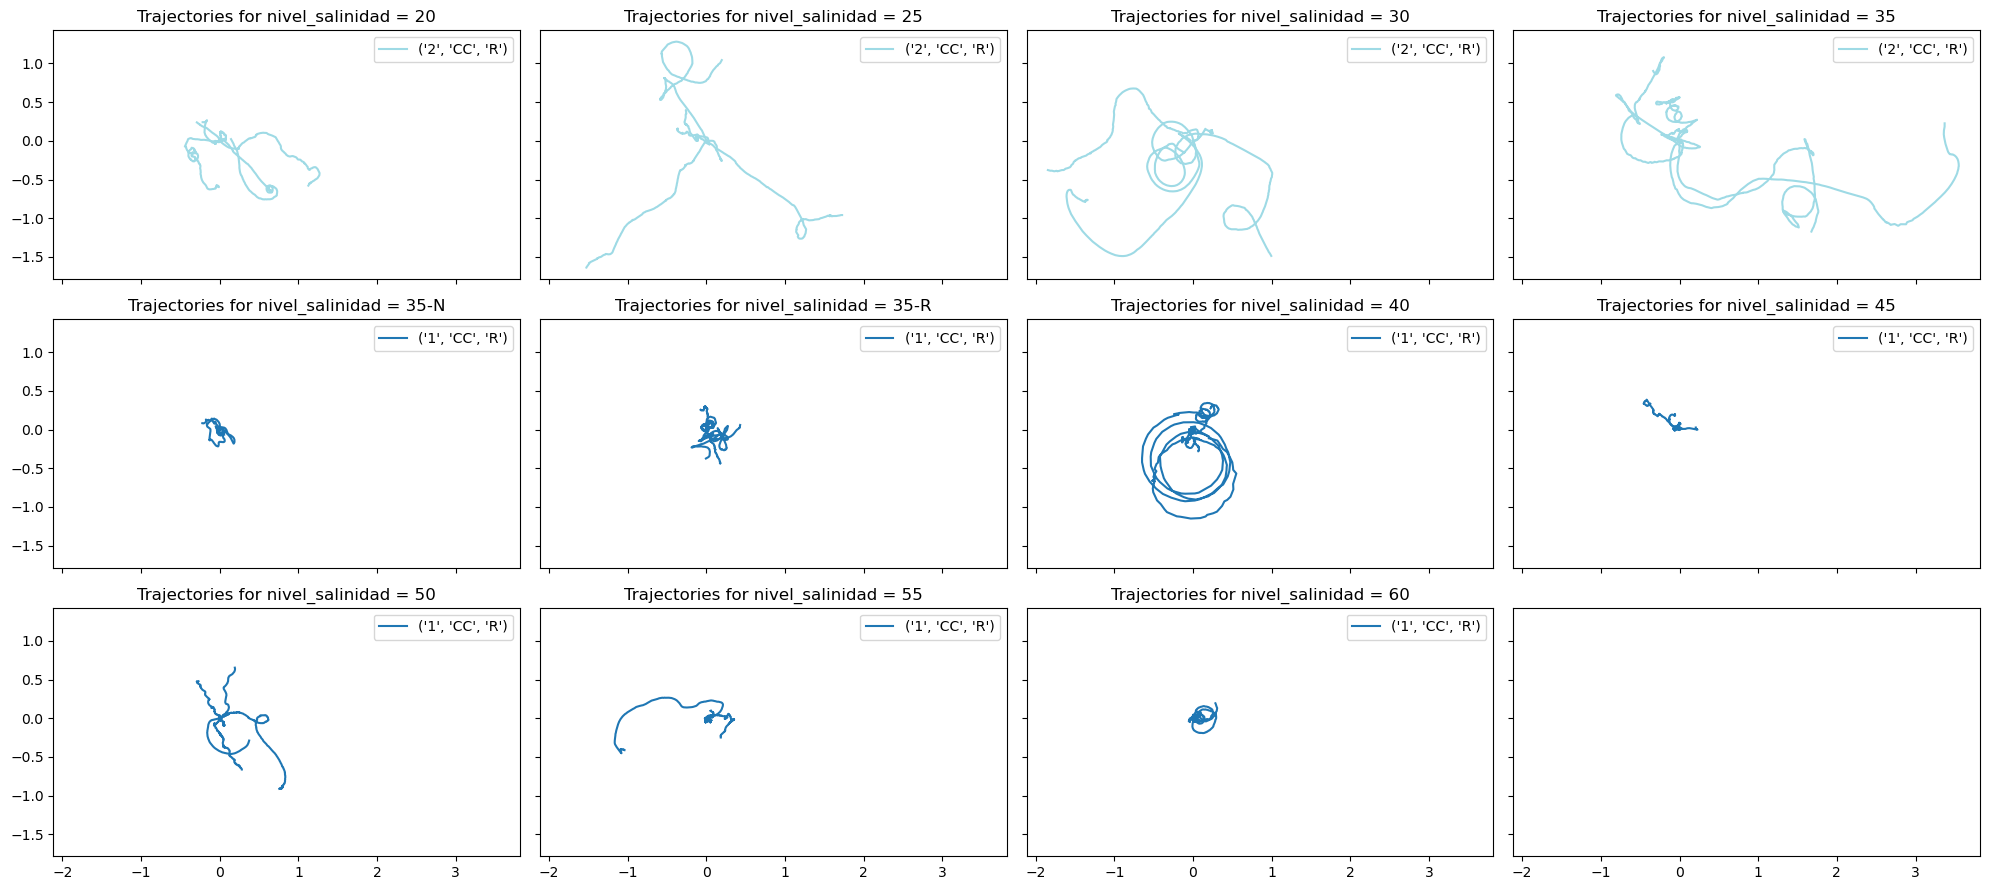

In [10]:

cc = df[(df.especie == 'CC') & (df.tratamiento == 'R')]
print(f"keys available to plot {df.keys()}")
visualization_by_salinity(cc, variable = 'position', dif = False)


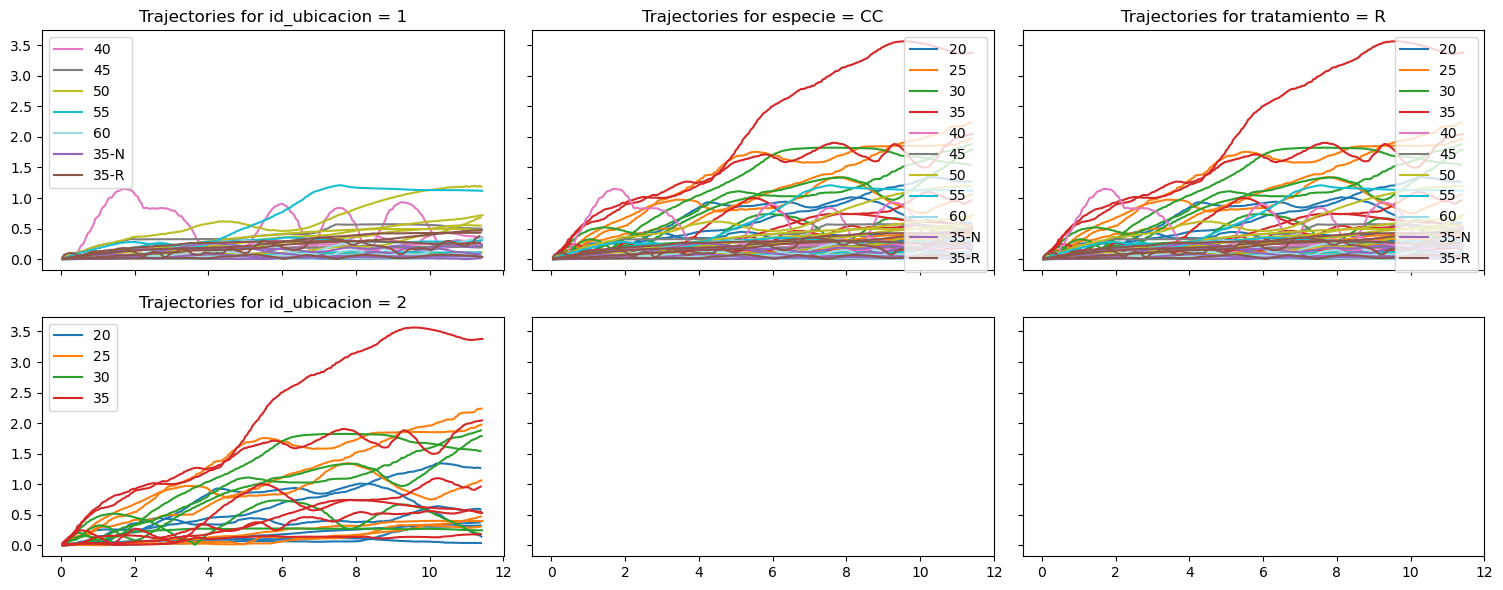

In [11]:
visualization_by_other_variables(cc, 'r', keys_to_group = ['id_ubicacion', 'especie', 'tratamiento'], dif = False)

In [12]:
df[df['id'] == 59]

,index,id,t,x,y,id_ubicacion,especie,tratamiento,salinidad,nombre_archivo,...,a,r,dr,theta_r,v_angular,a_angular,theta_v,curvatura,duracion_video_recortada,nivel_salinidad
10380,10380,59,0.050677,0.632607,-0.529299,1,CC,R,40,Video_006,...,11.472474,0.038933,0.484242,2.232510,13.019270,-600.302075,1.163179,36.532160,11.515,alta
10381,10381,59,0.108093,0.684163,-0.520449,1,CC,R,40,Video_006,...,7.821224,0.048260,-0.167108,0.961126,-20.660244,-30.713214,-0.650254,34.183465,11.515,alta
10382,10382,59,0.166016,0.675639,-0.562881,1,CC,R,40,Video_006,...,3.173040,0.019323,-0.283073,-0.148928,10.042764,94.935785,-2.292585,34.293501,11.515,alta
10383,10383,59,0.235544,0.639031,-0.557285,1,CC,R,40,Video_006,...,12.080619,0.017710,0.217707,2.986886,-19.671442,-437.136789,0.371049,36.680425,11.515,alta
10384,10384,59,0.278467,0.686978,-0.546192,1,CC,R,40,Video_006,...,8.921451,0.033438,0.599011,0.426156,-38.693491,28.010724,-0.179348,16.527878,11.515,alta
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10602,10602,59,11.208280,0.579180,-0.337246,1,CC,R,40,Video_006,...,1.032307,0.235815,-0.213994,-10.661376,-3.166227,-2.081139,0.099409,0.216196,11.515,alta
10603,10603,59,11.260020,0.608573,-0.334152,1,CC,R,40,Video_006,...,1.426343,0.230897,-0.135957,-10.786353,-3.233571,-6.670768,-0.020775,4.867375,11.515,alta
10604,10604,59,11.320120,0.665812,-0.340340,1,CC,R,40,Video_006,...,4.054400,0.219870,-0.012569,-11.037803,-4.009311,-17.259859,-0.047302,2.273072,11.515,alta
10605,10605,59,11.362840,0.702940,-0.340340,1,CC,R,40,Video_006,...,2.780763,0.224523,0.169640,-11.203780,-4.878816,-7.098303,-0.107970,3.504478,11.515,alta
